# Test Data Analysis Tools

This notebook will be used to explore basic functionality of CSV data import and handling followed by the plotting of time series data.
Here aer some assumptions we will use to start:
- The CSV contains one measurement per row.
- Each measurement channel occupies one column.
- A time variable is present, preferably in seconds.
- Measurement channels contain numeric data.
- The CSV has a header row containing the column names.

### Import Packages

In [5]:
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from matplotlib.backends.backend_pdf import PdfPages

import math

### Set plotting style

In [6]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["font.size"] = 9


### Configure the Input File

In [7]:
PROJECT_DIR = Path("..")

INPUT_DIR = PROJECT_DIR / "data" / "input"
OUTPUT_DIR = PROJECT_DIR / "data" / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CSV_FILE = INPUT_DIR / "simulated_sensor_data.csv"
TIME_COLUMN = None

### Import the CSV

In [8]:
def import_csv(file_path):

    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(f"File not found: {file_path}"
        )

    df = pd.read_csv(file_path)

    if df.empty:
        raise ValueError(f"CSV file contains no data.")

    if len(df.columns) == 0:
        raise ValueError(f"CSV file contains no columns.")

     # Remove accidental whitespace from column names
    df.columns = df.columns.astype(str).str.strip()

    return df

In [9]:
df = import_csv(CSV_FILE)

print(f"File imported successfully: {CSV_FILE.name}")
print(f"Number of samples: {len(df)}")
print(f"Number of columns: {len(df.columns)}")

File imported successfully: simulated_sensor_data.csv
Number of samples: 600
Number of columns: 15


### Inspect the Data

In [10]:
def inspect_data(df):

    print("COLUMN INFORMATION")
    print("-" * 50)

    for column in df.columns:

        print(
            f"{column:<30} "
            f"{df[column].dtype}"
        )

    print("\nDATA SUMMARY")
    print("-" * 50)

    display(df.describe(include="all").T)

    print("\nFIRST 5 SAMPLES")
    print("-" * 50)

    display(df.head())

In [11]:
inspect_data(df)

COLUMN INFORMATION
--------------------------------------------------
Time_s                         int64
Temperature_C                  float64
Pressure_bar                   float64
Flow_L_min                     float64
Vibration_mm_s                 float64
Voltage_V                      float64
Current_A                      float64
Humidity_pct                   float64
Speed_RPM                      float64
Torque_Nm                      float64
Acceleration_m_s2              float64
Displacement_mm                float64
Power_kW                       float64
Conductivity_mS                float64
Level_pct                      float64

DATA SUMMARY
--------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
Time_s,600.0,299.500000,173.349358,0.0000,149.750000,299.50000,449.250000,599.0000
Temperature_C,600.0,25.725483,1.829365,22.1700,24.020000,25.81500,27.402500,29.3600
Pressure_bar,600.0,5.372987,0.294019,4.8670,5.111000,5.37650,5.621500,5.9730
Flow_L_min,600.0,123.295817,11.073653,100.8400,113.470000,123.39500,133.232500,145.1900
Vibration_mm_s,600.0,3.809000,0.746921,2.2020,3.160250,3.85650,4.470250,5.2630
Voltage_V,600.0,230.322950,1.456287,227.6000,228.967500,230.29500,231.675000,233.1100
Current_A,600.0,12.145015,1.091759,10.2430,11.118750,12.17850,13.179750,14.0770
Humidity_pct,600.0,45.868167,3.885993,37.1000,42.400000,46.30000,49.400000,52.3000
Speed_RPM,600.0,1513.622833,57.341002,1399.3000,1460.600000,1512.10000,1564.425000,1627.9000
Torque_Nm,600.0,88.305100,8.773526,69.0100,80.287500,88.06500,96.285000,104.7500



FIRST 5 SAMPLES
--------------------------------------------------


,Time_s,Temperature_C,Pressure_bar,Flow_L_min,Vibration_mm_s,Voltage_V,Current_A,Humidity_pct,Speed_RPM,Torque_Nm,Acceleration_m_s2,Displacement_mm,Power_kW,Conductivity_mS,Level_pct
0,0,24.94,5.112,122.61,3.559,229.80,12.029,46.0,1485.0,86.16,-0.5341,9.559,17.81,1.7668,65.67
1,1,25.29,5.213,126.69,3.661,229.58,12.323,46.3,1500.0,89.95,0.0986,9.866,17.38,1.8343,65.99
2,2,25.23,5.211,126.55,3.909,230.00,12.619,46.8,1511.7,91.70,0.2633,10.063,18.44,1.8989,67.12
3,3,25.44,5.213,129.76,4.086,230.13,12.780,46.6,1517.4,95.50,0.2023,10.101,18.81,1.9360,69.17
4,4,25.91,5.240,130.33,4.036,230.40,12.900,47.2,1521.8,94.51,0.7150,10.388,19.20,1.9362,69.63


### Identify the Time Column
We want to be able to identify the time data column in case it is not the first column.


In [12]:
def identify_time_column(df, requested_column=None):

    if requested_column is not None:

        if requested_column not in df.columns:
            raise ValueError(
                f"Time column '{requested_column}' not found."
            )

        return requested_column

    candidates = [
        "time",
        "time (s)",
        "time_s",
        "timestamp",
        "elapsed time",
        "elapsed_time",
        "test time",
        "test_time",
        "seconds"
    ]

    normalized_columns = {
        str(column).strip().lower(): column
        for column in df.columns
    }

    for candidate in candidates:

        if candidate in normalized_columns:
            return normalized_columns[candidate]

    return None

### Identify Numeric Channels

In [13]:
def identify_numeric_channels(df, time_column=None):

    numeric_columns = df.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    if time_column in numeric_columns:
        numeric_columns.remove(time_column)

    return numeric_columns

### Execute Identification of Time and Numeric Channels

In [14]:
time_column = identify_time_column(
    df,
    TIME_COLUMN
)

channels = identify_numeric_channels(
    df,
    time_column
)

print("TIME VARIABLE")
print(time_column if time_column else "Not identified")

print("\nMEASUREMENT CHANNELS")
for channel in channels:
    print(channel)

print(f"\nTotal measurement channels: {len(channels)}")

TIME VARIABLE
Time_s

MEASUREMENT CHANNELS
Temperature_C
Pressure_bar
Flow_L_min
Vibration_mm_s
Voltage_V
Current_A
Humidity_pct
Speed_RPM
Torque_Nm
Acceleration_m_s2
Displacement_mm
Power_kW
Conductivity_mS
Level_pct

Total measurement channels: 14


### Horizontal Axis

In [15]:
def prepare_time_axis(df, time_column):

    if time_column is None:

        return (
            np.arange(len(df)),
            "Sample Number",
            False
        )

    raw_time = df[time_column]

    numeric_time = pd.to_numeric(
        raw_time,
        errors="coerce"
    )

    if numeric_time.notna().mean() >= 0.8:

        return (
            numeric_time,
            time_column,
            False
        )

    datetime_time = pd.to_datetime(
        raw_time,
        errors="coerce",
        format="mixed"
    )

    if datetime_time.notna().mean() >= 0.8:

        return (
            datetime_time,
            time_column,
            True
        )

    print(
        "Warning: Time column could not be interpreted. "
        "Using sample number instead."
    )

    return (
        np.arange(len(df)),
        "Sample Number",
        False
    )

In [16]:
time_values, time_label, is_datetime = prepare_time_axis(
    df,
    time_column
)

## Generate Time Histories

For this first version here are the assumptions we will use to keep it simple.

1. Each measurement channel gets its own plot.
2. All plots use the same horizontal time axis.
3. Each channel has an independent vertical axis.
4. The vertical axis is automatically scaled to the available data.
5. Plots are arranged four per PDF page.


### Create Plotting Function

In [21]:
from IPython.display import display


def plot_time_histories(
    df,
    channels,
    time_values,
    time_label,
    is_datetime=False,
    channels_per_page=4
):

    valid_channels = [
        channel for channel in channels
        if pd.to_numeric(
            df[channel],
            errors="coerce"
        ).notna().sum() >= 2
    ]

    if not valid_channels:
        raise ValueError("No valid numeric channels found.")

    figures = []

    pages = math.ceil(
        len(valid_channels) / channels_per_page
    )

    for page in range(pages):

        start = page * channels_per_page
        end = start + channels_per_page

        page_channels = valid_channels[start:end]

        fig, axes = plt.subplots(
            2, 2,
            figsize=(11.7, 8.3),
            sharex=True
        )

        axes = axes.flatten()

        for ax, channel in zip(axes, page_channels):

            y = pd.to_numeric(
                df[channel],
                errors="coerce"
            )

            ax.plot(
                time_values,
                y,
                linewidth=0.8
            )

            ax.set_title(channel)
            ax.set_ylabel(channel)
            ax.set_xlabel(time_label)
            ax.grid(True, alpha=0.35)

            if is_datetime:
                ax.xaxis.set_major_formatter(
                    mdates.DateFormatter("%H:%M:%S")
                )

        for ax in axes[len(page_channels):]:
            ax.set_visible(False)

        fig.suptitle(
            f"Test Data Time Histories — "
            f"Page {page + 1} of {pages}",
            fontsize=14,
            fontweight="bold"
        )

        fig.tight_layout(
            rect=[0, 0, 1, 0.95]
        )

        display(fig)

        figures.append(fig)

    return figures

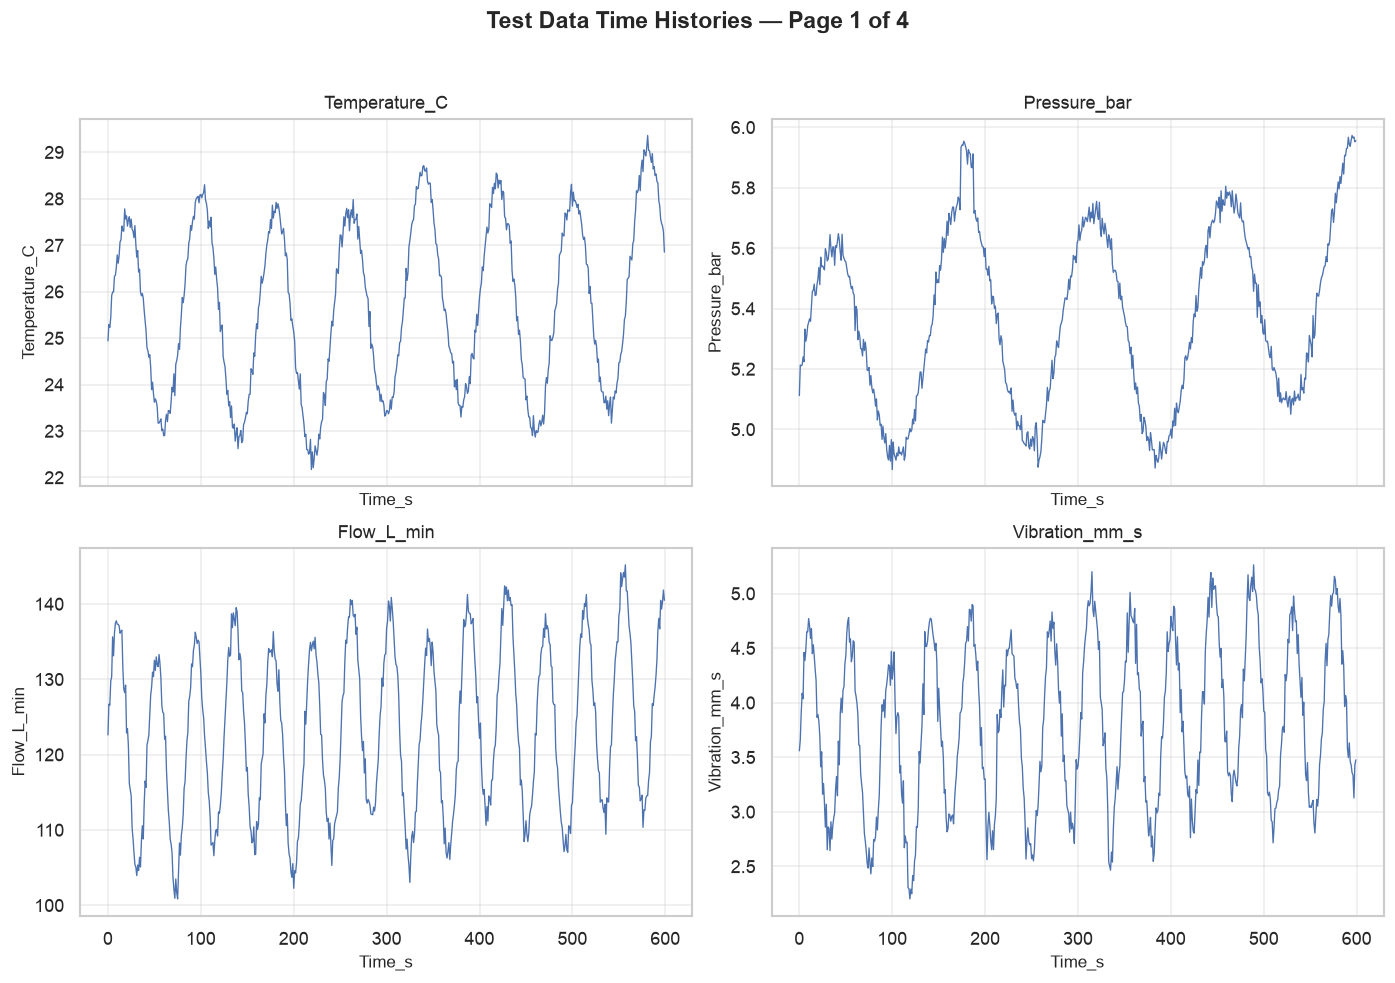

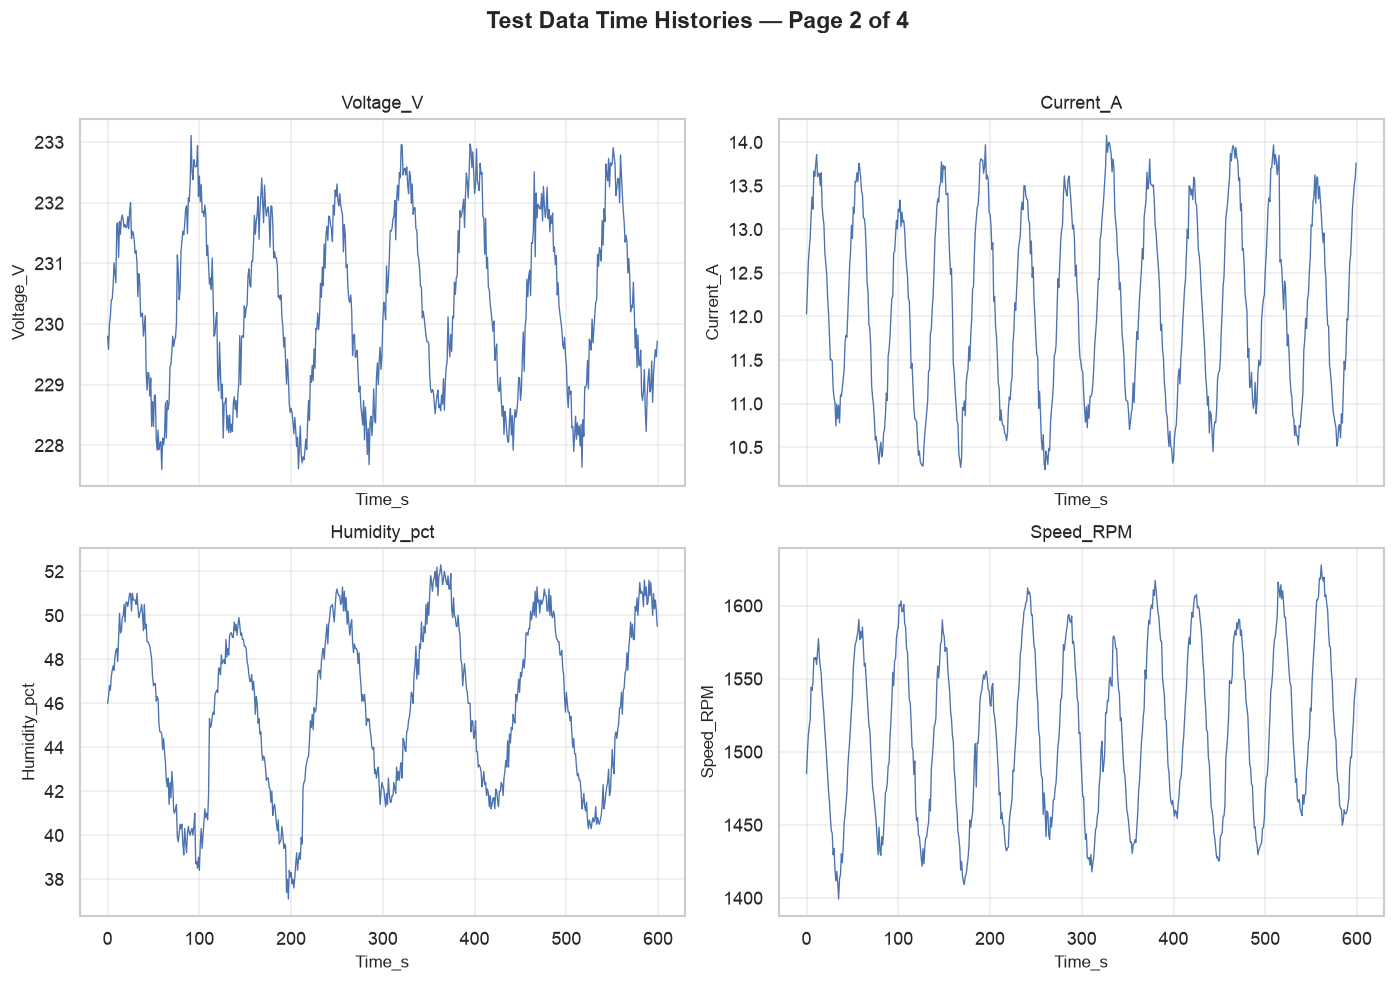

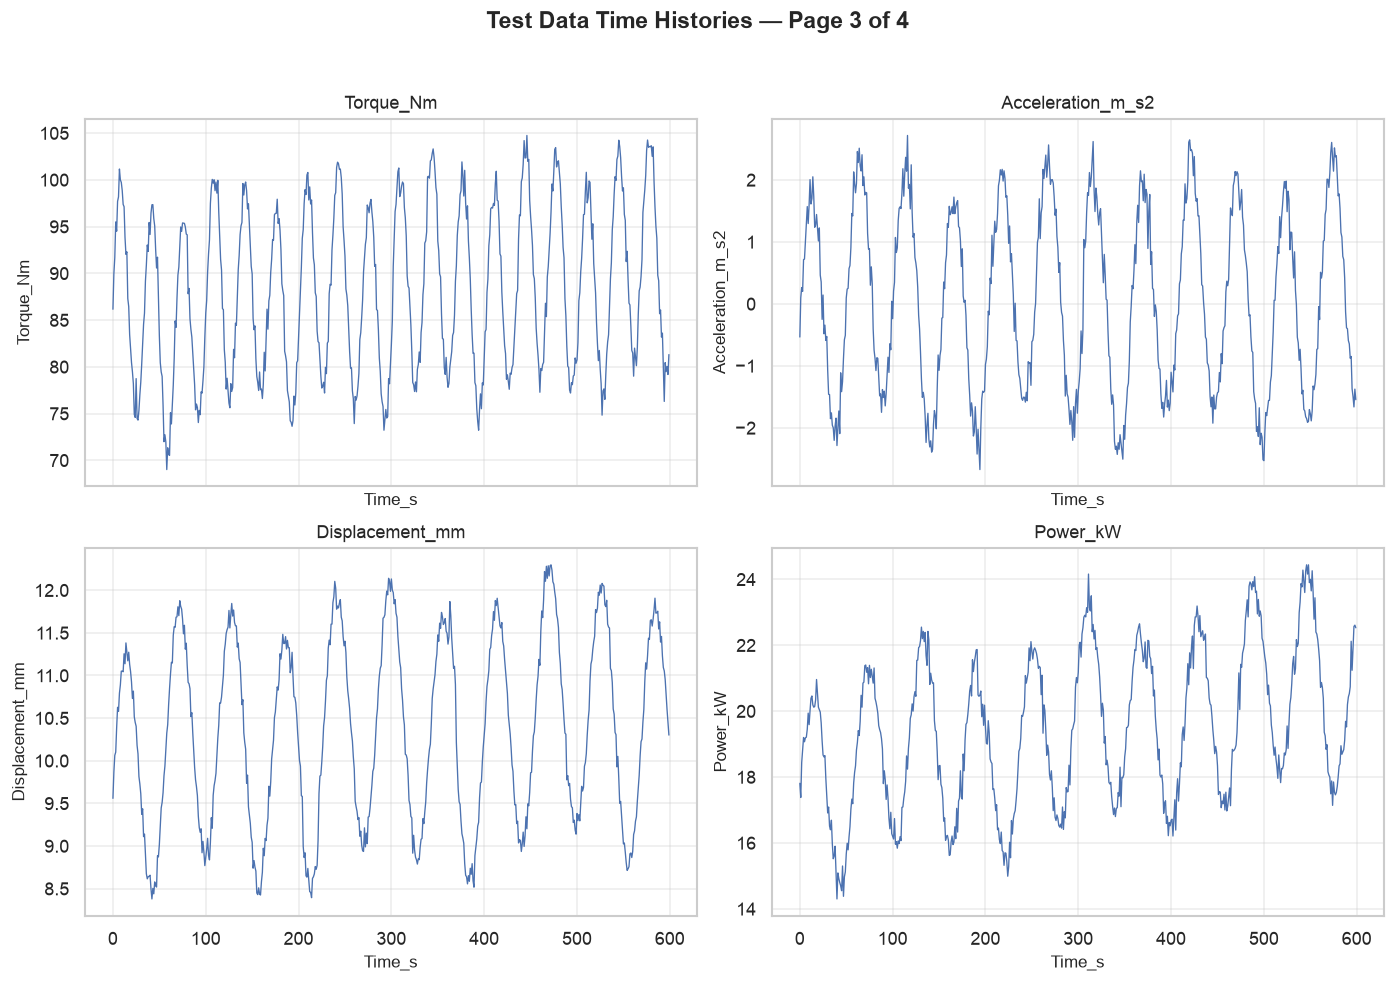

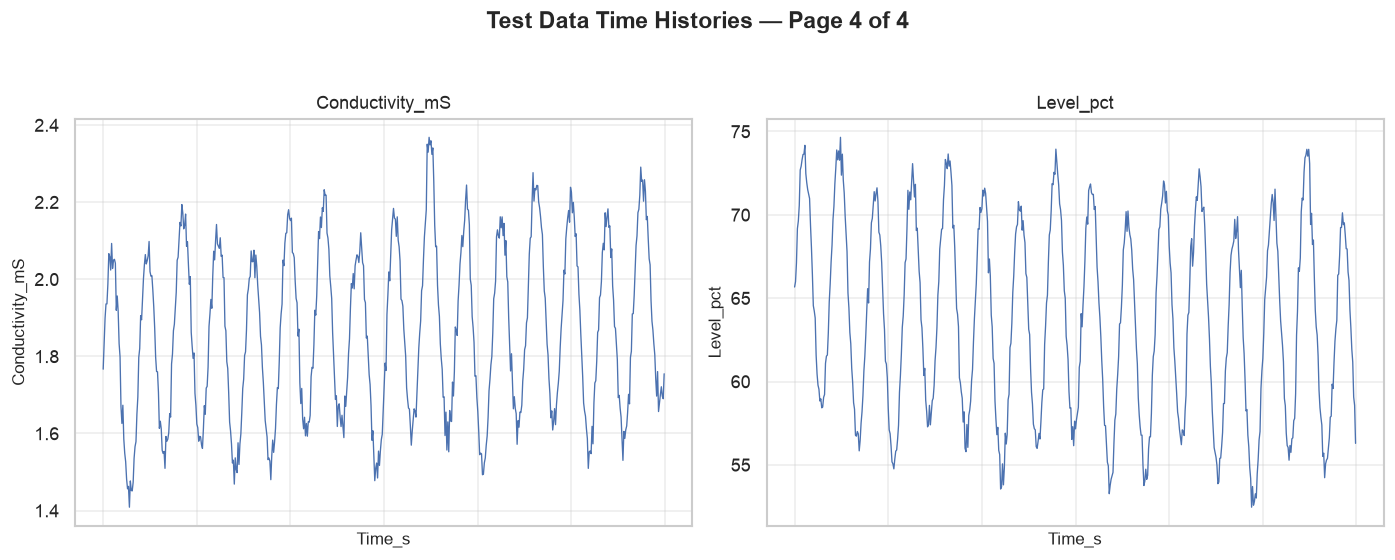

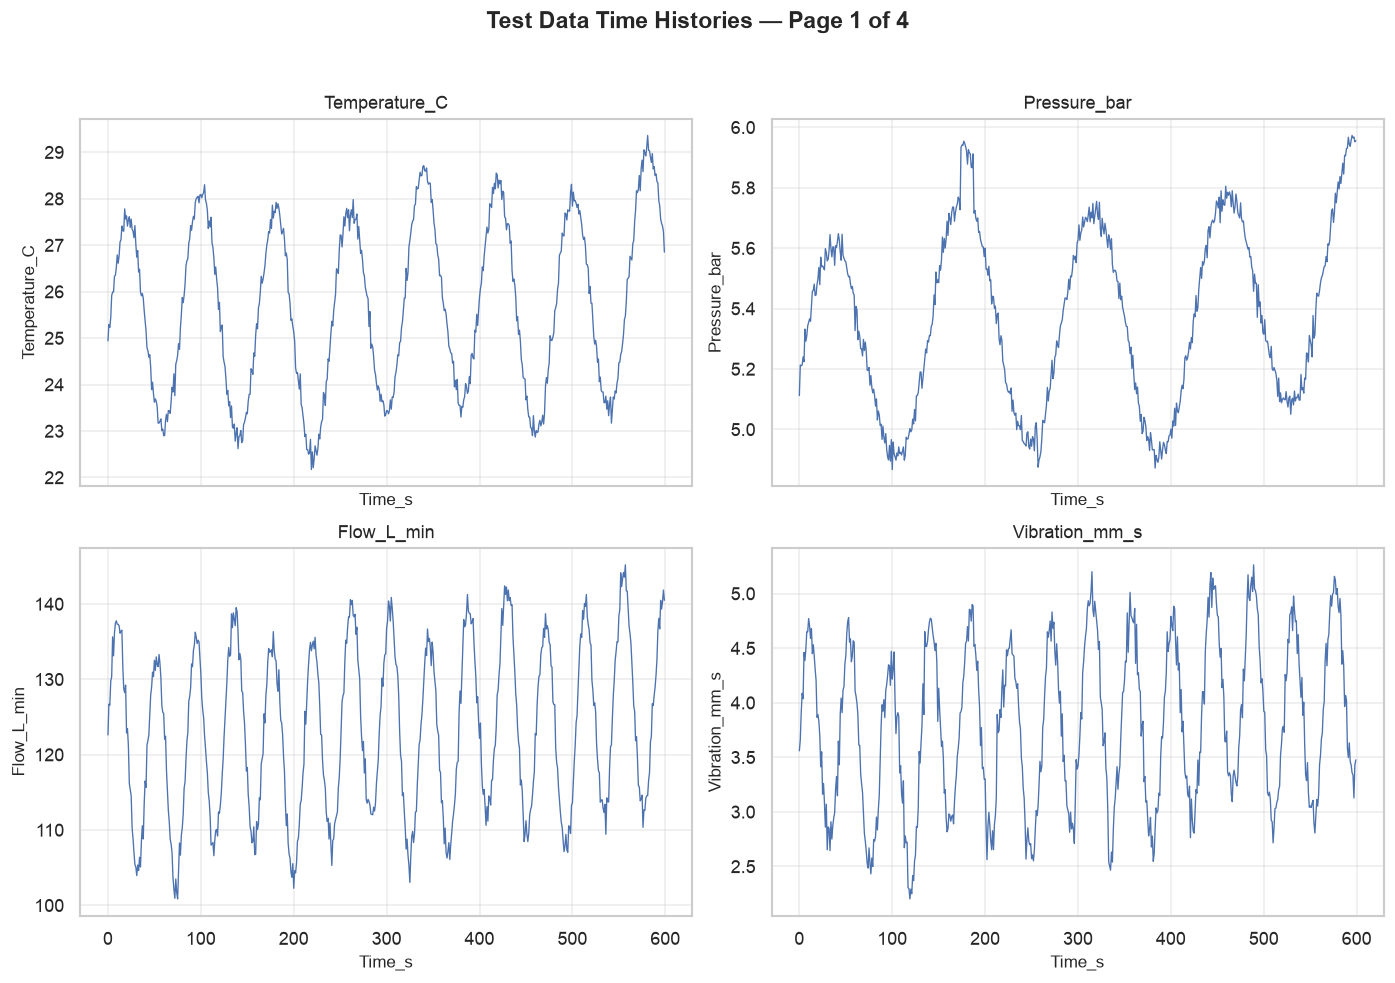

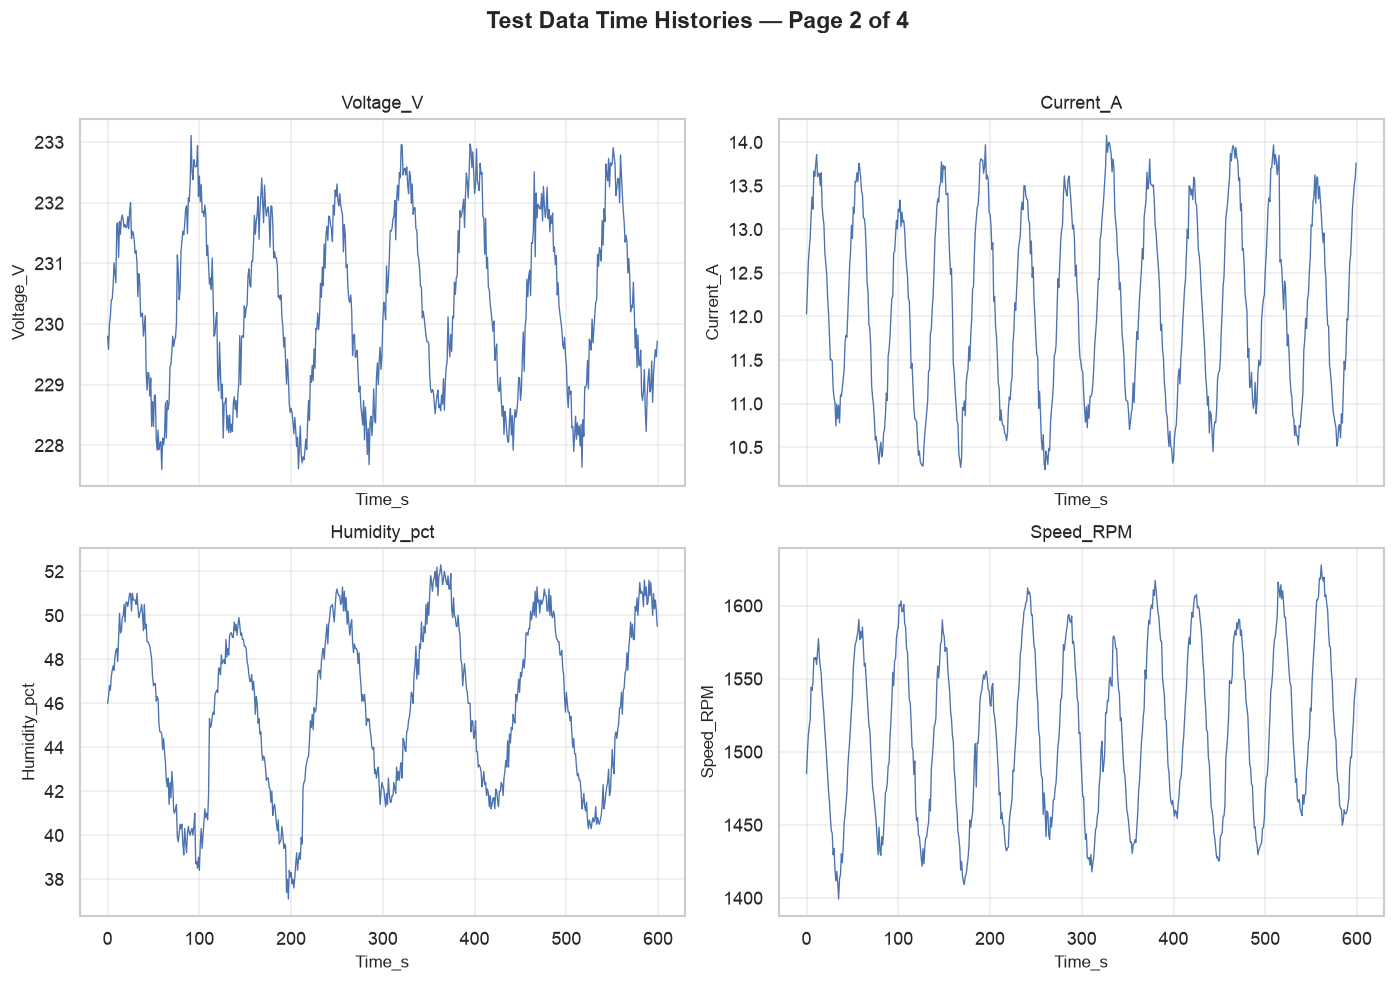

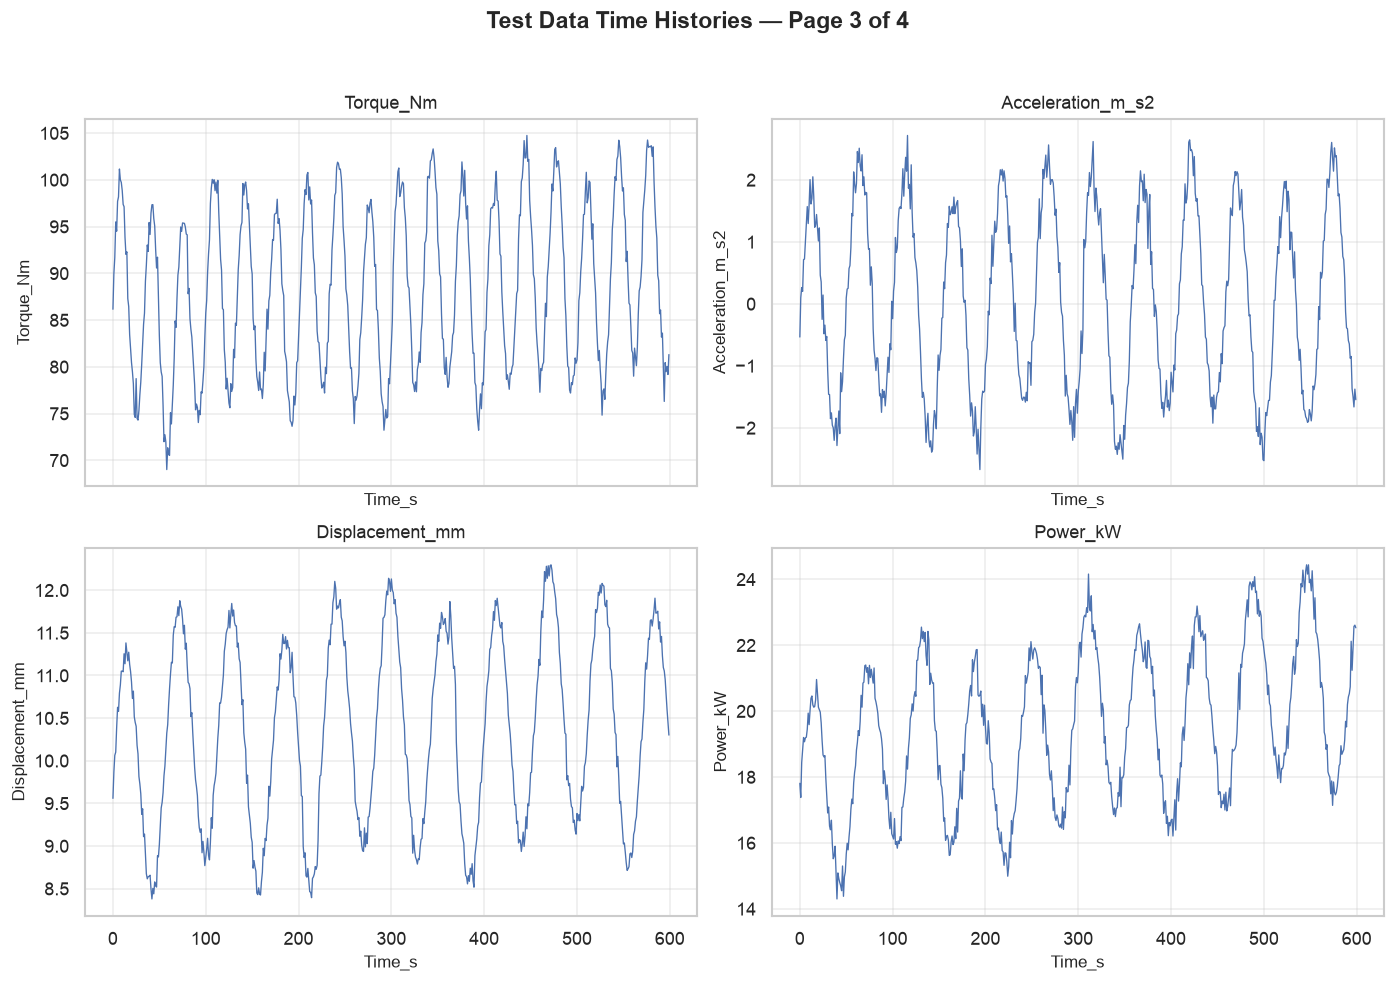

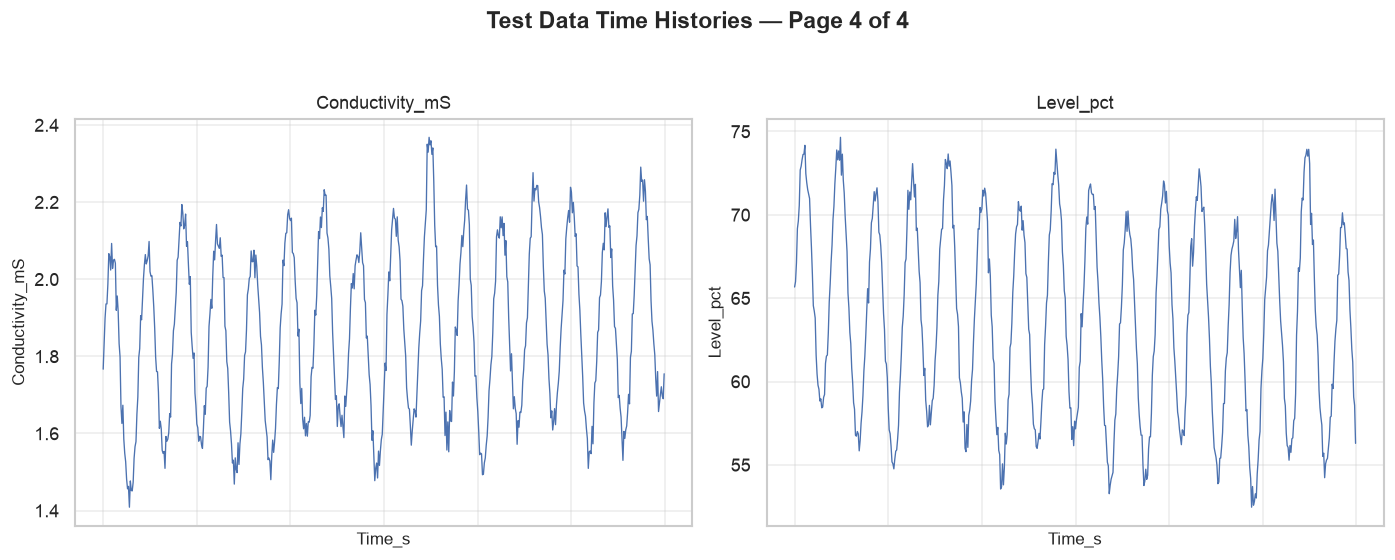

In [22]:
figures = list(
    plot_time_histories(
        df=df,
        channels=channels,
        time_values=time_values,
        time_label=time_label,
        is_datetime=is_datetime
    )
)

### Export PDF Report

In [23]:
def export_pdf(figures, output_file):

    output_file = Path(output_file)

    output_file.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    with PdfPages(output_file) as pdf:

        for fig in figures:
            pdf.savefig(
                fig,
                bbox_inches="tight"
            )

    print(f"PDF report generated: {output_file}")

In [ ]:
PDF_FILE = OUTPUT_DIR / "test_data_report.pdf"

export_pdf(
    figures,
    PDF_FILE
)

for fig in figures:
    plt.close(fig)

PDF report generated: ../data/output/test_data_report.pdf
